# Predicting unseen perturbation effects

This notebook evaluates whether control-derived gene-context features can predict the expression effect of a perturbation excluded entirely from training. Perturbations are split by identity, and outcome PCA is fit only on training effects.

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_PATH = "../data/raw/replogle22rpe1.h5ad"
MIN_CELLS = 100
N_CONTEXT_GENES = 500
N_EFFECT_COMPONENTS = 50
TEST_SIZE = 0.20
RANDOM_SEED = 42

adata = sc.read_h5ad(DATA_PATH)
print(adata)

AnnData object with n_obs × n_vars = 240774 × 8749
    obs: 'perturbation'


## Select perturbations with measurable targets

A control-derived correlation vector requires the perturbation target to be present in the measured gene set. Targets absent from `adata.var_names` are excluded explicitly.

In [2]:
counts = adata.obs["perturbation"].value_counts().drop("control")
quality_controlled = counts[counts >= MIN_CELLS].index.tolist()
measured_genes = set(adata.var_names)
eligible_perturbations = [
    perturbation
    for perturbation in quality_controlled
    if perturbation in measured_genes
]
excluded_targets = [
    perturbation
    for perturbation in quality_controlled
    if perturbation not in measured_genes
]

print(f"Perturbations with at least {MIN_CELLS} cells: {len(quality_controlled)}")
print(f"Eligible perturbations with measured target genes: {len(eligible_perturbations)}")
print(f"Excluded because target gene is not measured: {len(excluded_targets)}")

Perturbations with at least 100 cells: 783
Eligible perturbations with measured target genes: 659
Excluded because target gene is not measured: 124


## Derive gene-context features from control cells only

The 500 highest-variance genes in untreated cells define a shared context space. Each perturbation target is represented by its control-cell expression correlation with those genes. No perturbation outcome contributes to these input features.

In [3]:
control = adata[adata.obs["perturbation"] == "control"]
control_x = control.X

control_mean = np.asarray(control_x.mean(axis=0)).flatten()
if sparse.issparse(control_x):
    control_squared_mean = np.asarray(control_x.power(2).mean(axis=0)).flatten()
else:
    control_squared_mean = np.mean(np.square(control_x), axis=0)
control_variance = np.maximum(control_squared_mean - np.square(control_mean), 0)

context_indices = np.argsort(control_variance)[-N_CONTEXT_GENES:][::-1]
target_indices = adata.var_names.get_indexer(eligible_perturbations)

context_expression = control_x[:, context_indices]
target_expression = control_x[:, target_indices]
if sparse.issparse(context_expression):
    context_expression = context_expression.toarray()
if sparse.issparse(target_expression):
    target_expression = target_expression.toarray()

context_expression = np.asarray(context_expression, dtype=np.float64)
target_expression = np.asarray(target_expression, dtype=np.float64)

context_std = context_expression.std(axis=0)
target_std = target_expression.std(axis=0)
context_std[context_std == 0] = 1
target_std[target_std == 0] = 1

context_z = (context_expression - context_expression.mean(axis=0)) / context_std
target_z = (target_expression - target_expression.mean(axis=0)) / target_std
assert np.isfinite(context_z).all() and np.isfinite(target_z).all()
with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    gene_context = target_z.T @ context_z / control.n_obs
assert np.isfinite(gene_context).all()

context_df = pd.DataFrame(
    gene_context,
    index=eligible_perturbations,
    columns=adata.var_names[context_indices],
)

print("Gene-context feature matrix:", context_df.shape)
print("Finite feature values:", bool(np.isfinite(context_df.to_numpy()).all()))

Gene-context feature matrix: (659, 500)
Finite feature values: True


## Calculate measured perturbation effects

In [4]:
labels = adata.obs["perturbation"].to_numpy()
states = {}

for perturbation in eligible_perturbations:
    positions = np.flatnonzero(labels == perturbation)
    states[perturbation] = np.asarray(
        adata[positions].X.mean(axis=0)
    ).flatten()

state_df = pd.DataFrame(states, index=adata.var_names).T
effect_df = state_df.subtract(control_mean, axis="columns")

print("Canonical state matrix:", state_df.shape)
print("Perturbation effect matrix:", effect_df.shape)

Canonical state matrix: (659, 8749)
Perturbation effect matrix: (659, 8749)


## Split by perturbation identity

Held-out perturbation names are never included in model fitting. The fixed random seed makes this experimental split reproducible.

In [5]:
train_perts, test_perts = train_test_split(
    eligible_perturbations,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
)

print("Training perturbations:", len(train_perts))
print("Held-out perturbations:", len(test_perts))
print("Identity overlap:", len(set(train_perts) & set(test_perts)))
print("First held-out perturbations:", test_perts[:10])

Training perturbations: 527
Held-out perturbations: 132
Identity overlap: 0
First held-out perturbations: ['LSM10', 'CCNC', 'ATP5PD', 'SIN3A', 'SART3', 'RBMX2', 'KCTD10', 'MRPL3', 'ANKS6', 'UBR5']


## Fit effect PCA on training perturbations only

In [6]:
effect_pca = PCA(n_components=N_EFFECT_COMPONENTS, random_state=RANDOM_SEED)
train_effects = effect_df.loc[train_perts].to_numpy(dtype=np.float64)
assert np.isfinite(train_effects).all()
with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    train_effect_pca = effect_pca.fit_transform(train_effects)
assert np.isfinite(train_effect_pca).all()

print("Reduced training targets:", train_effect_pca.shape)
print(f"Training-effect variance explained: {effect_pca.explained_variance_ratio_.sum():.2%}")

Reduced training targets: (527, 50)
Training-effect variance explained: 75.10%


## Predict unseen effects with Ridge regression

Feature scaling and Ridge regularization are fit using training perturbations only. `RidgeCV` selects regularization strength using only those training examples.

In [7]:
model = make_pipeline(
    StandardScaler(),
    RidgeCV(
        alphas=np.logspace(-2, 4, 13),
        cv=5,
        scoring="neg_mean_squared_error",
    ),
)
with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    model.fit(context_df.loc[train_perts], train_effect_pca)
    predicted_effect_pca = model.predict(context_df.loc[test_perts])
    predicted_effects = effect_pca.inverse_transform(predicted_effect_pca)
assert np.isfinite(predicted_effects).all()
actual_effects = effect_df.loc[test_perts].to_numpy()
average_effect = effect_df.loc[train_perts].mean(axis=0).to_numpy()
average_predictions = np.repeat(
    average_effect[np.newaxis, :],
    len(test_perts),
    axis=0,
)
null_predictions = np.zeros_like(actual_effects)

actual_states = state_df.loc[test_perts].to_numpy()
predicted_states = control_mean + predicted_effects
average_predicted_states = control_mean + average_predictions
null_predicted_states = np.repeat(
    control_mean[np.newaxis, :],
    len(test_perts),
    axis=0,
)

assert np.isfinite(predicted_states).all()

print("Selected Ridge alpha:", model.named_steps["ridgecv"].alpha_)

Selected Ridge alpha: 1000.0


## Evaluate held-out perturbations

State-space MSE is identical to effect-space MSE because the same control state is added to predictions and observations. Pearson correlation is calculated between predicted and actual effect vectors.

In [8]:
def rowwise_pearson(actual, predicted):
    actual_centered = actual - actual.mean(axis=1, keepdims=True)
    predicted_centered = predicted - predicted.mean(axis=1, keepdims=True)
    numerator = np.sum(actual_centered * predicted_centered, axis=1)
    denominator = np.sqrt(
        np.sum(actual_centered ** 2, axis=1)
        * np.sum(predicted_centered ** 2, axis=1)
    )
    return np.divide(
        numerator,
        denominator,
        out=np.full_like(numerator, np.nan),
        where=denominator != 0,
    )


results = pd.DataFrame({
    "perturbation": test_perts,
    "cell_count": counts.loc[test_perts].to_numpy(),
    "null_mse": np.mean((actual_states - null_predicted_states) ** 2, axis=1),
    "average_effect_mse": np.mean((actual_states - average_predicted_states) ** 2, axis=1),
    "gene_context_ridge_mse": np.mean((actual_states - predicted_states) ** 2, axis=1),
    "average_effect_pearson": rowwise_pearson(actual_effects, average_predictions),
    "gene_context_ridge_pearson": rowwise_pearson(actual_effects, predicted_effects),
})
results["ridge_vs_null_improvement_percent"] = (
    (results["null_mse"] - results["gene_context_ridge_mse"])
    / results["null_mse"]
    * 100
)

comparison = pd.DataFrame({
    "model": ["No change", "Average training effect", "Gene-context Ridge"],
    "held_out_mse": [
        np.mean((actual_states - null_predicted_states) ** 2),
        np.mean((actual_states - average_predicted_states) ** 2),
        np.mean((actual_states - predicted_states) ** 2),
    ],
    "median_effect_pearson": [
        np.nan,
        results["average_effect_pearson"].median(),
        results["gene_context_ridge_pearson"].median(),
    ],
})

comparison

,model,held_out_mse,median_effect_pearson
0,No change,0.004396,NaN
1,Average training effect,0.003735,0.292948
2,Gene-context Ridge,0.003668,0.288035


In [9]:
print(
    "Held-out perturbations where Ridge beats no-change:",
    int((results["gene_context_ridge_mse"] < results["null_mse"]).sum()),
    "/",
    len(results),
)
print(
    "Median Ridge improvement over no-change:",
    f'{results["ridge_vs_null_improvement_percent"].median():.2f}%',
)

results.sort_values("gene_context_ridge_pearson", ascending=False).head(10)

Held-out perturbations where Ridge beats no-change: 59 / 132
Median Ridge improvement over no-change: -6.54%


,perturbation,cell_count,null_mse,average_effect_mse,gene_context_ridge_mse,average_effect_pearson,gene_context_ridge_pearson,ridge_vs_null_improvement_percent
114,PLK4,174,0.012501,0.007741,0.005986,0.878195,0.927952,52.115153
64,CDT1,106,0.015869,0.010223,0.008426,0.905004,0.900515,46.900936
60,HAUS8,172,0.006388,0.003409,0.002686,0.831802,0.886660,57.947280
94,RCC1,186,0.007040,0.003735,0.003059,0.861462,0.875739,56.544804
36,NDC80,100,0.009089,0.005080,0.004068,0.889655,0.874597,55.246525
128,RPLP0,114,0.019765,0.014496,0.011306,0.771527,0.873503,42.799190
41,HAUS4,155,0.012235,0.007587,0.007414,0.867585,0.861860,39.399721
28,SHQ1,150,0.009586,0.005678,0.005442,0.849524,0.852310,43.234242
26,DCTN4,114,0.017271,0.011492,0.011739,0.883286,0.846372,32.030775
24,HSPE1,102,0.018811,0.013358,0.010398,0.801389,0.828690,44.722925


## Inspect one representative held-out prediction

The example nearest the median Ridge correlation is used to avoid selecting only the best result.

In [10]:
median_correlation = results["gene_context_ridge_pearson"].median()
example_row = (
    results.assign(
        distance_from_median=(
            results["gene_context_ridge_pearson"] - median_correlation
        ).abs()
    )
    .sort_values("distance_from_median")
    .iloc[0]
)
example_perturbation = example_row["perturbation"]
example_index = test_perts.index(example_perturbation)

example_effects = pd.DataFrame({
    "gene": adata.var_names,
    "actual_effect": actual_effects[example_index],
    "predicted_effect": predicted_effects[example_index],
})
example_effects["actual_absolute_effect"] = example_effects["actual_effect"].abs()
example_effects["predicted_absolute_effect"] = example_effects["predicted_effect"].abs()

print("Held-out perturbation:", example_perturbation)
print(f'Pearson r: {example_row["gene_context_ridge_pearson"]:.3f}')
print(f'MSE: {example_row["gene_context_ridge_mse"]:.6f}')
print("\nTop actual changes:")
display(
    example_effects
    .sort_values("actual_absolute_effect", ascending=False)
    [["gene", "actual_effect", "predicted_effect"]]
    .head(10)
)
print("Top predicted changes:")
display(
    example_effects
    .sort_values("predicted_absolute_effect", ascending=False)
    [["gene", "actual_effect", "predicted_effect"]]
    .head(10)
)

Held-out perturbation: ZNF706
Pearson r: 0.290
MSE: 0.001153

Top actual changes:


,gene,actual_effect,predicted_effect
3858,ZNF706,-0.583097,-0.036628
4922,ARL2,-0.571157,-0.042116
2577,PHAX,-0.308916,-0.002140
4704,CTSD,-0.232431,-0.016921
5571,IFT81,-0.230765,-0.007285
2840,HIST1H4C,-0.200356,-0.193713
4290,DPP7,-0.194708,0.017069
8042,ID1,0.178097,-0.039544
5124,TAGLN,0.149117,0.098876
3004,MCM3,-0.148996,-0.111444


Top predicted changes:


,gene,actual_effect,predicted_effect
2196,H2AFZ,-0.093522,-0.300074
5332,TUBA1B,-0.070103,-0.288335
4663,MKI67,-0.090222,-0.271750
140,STMN1,-0.072583,-0.246586
5721,HMGB1,-0.025416,-0.237029
780,CENPF,-0.041036,-0.232786
4294,TUBB4B,-0.039961,-0.222274
2949,CDKN1A,0.044788,0.218420
144,HMGN2,-0.098342,-0.217966
1445,PTMA,-0.011592,-0.205542


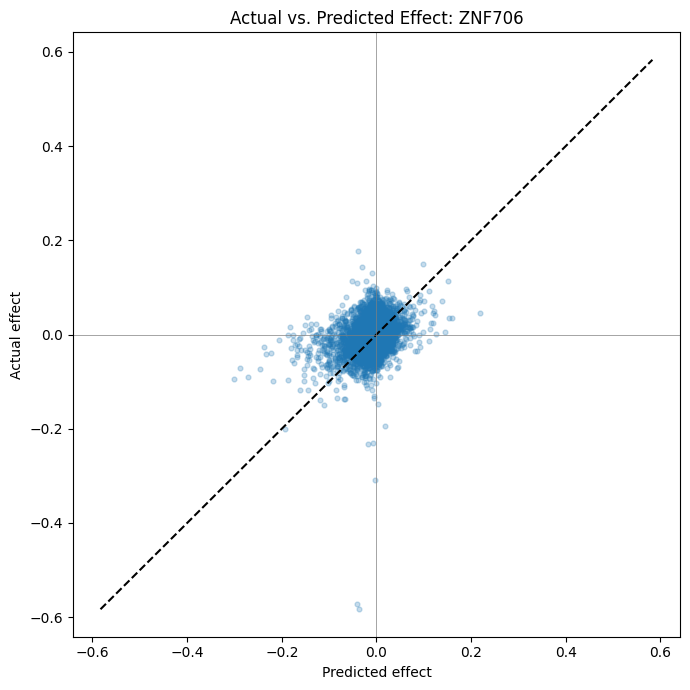

In [11]:
plt.figure(figsize=(7, 7))
plt.scatter(
    predicted_effects[example_index],
    actual_effects[example_index],
    alpha=0.25,
    s=12,
)
plot_limit = max(
    np.abs(predicted_effects[example_index]).max(),
    np.abs(actual_effects[example_index]).max(),
)
plt.plot([-plot_limit, plot_limit], [-plot_limit, plot_limit], "--", color="black")
plt.axhline(0, color="grey", linewidth=0.5)
plt.axvline(0, color="grey", linewidth=0.5)
plt.xlabel("Predicted effect")
plt.ylabel("Actual effect")
plt.title(f"Actual vs. Predicted Effect: {example_perturbation}")
plt.tight_layout()
plt.show()